In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=sns.load_dataset("titanic")
#df=pd.load_csv('Iris.csv')

In [3]:
df.head()
#df.tail(10)
#df.shape
#df.info()
#df.describe()



,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df["survived"].value_counts()

,count
survived,
0,549
1,342


In [5]:
df.duplicated().sum()

np.int64(107)

In [6]:
df=df.drop_duplicates()

In [7]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,106
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [8]:
df.drop(['deck','embark_town','alone','alive','adult_male','who','class'],axis=1,inplace=True)

In [9]:
mv=df["age"].median()
df['age']=df['age'].fillna(mv)



In [10]:
df=df.dropna()

In [11]:
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.00,1,0,7.2500,S
1,1,1,female,38.00,1,0,71.2833,C
2,1,3,female,26.00,0,0,7.9250,S
3,1,1,female,35.00,1,0,53.1000,S
4,0,3,male,35.00,0,0,8.0500,S
5,0,3,male,28.25,0,0,8.4583,Q
6,0,1,male,54.00,0,0,51.8625,S
7,0,3,male,2.00,3,1,21.0750,S
8,1,3,female,27.00,0,2,11.1333,S
9,1,2,female,14.00,1,0,30.0708,C


In [12]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0


<Axes: ylabel='age'>

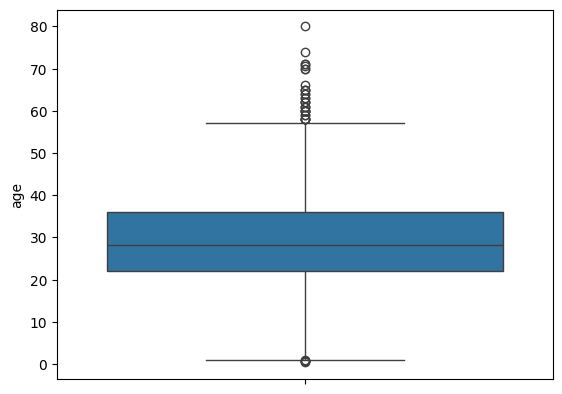

In [13]:
sns.boxplot(df["age"])

In [14]:
q1=df["age"].quantile(0.25)
q3=df["age"].quantile(0.75)
iqr=q3-q1
upper_bound=q3+1.5*iqr
lower_bound=q1-1.5*iqr
df["age"]=df["age"].clip(upper=upper_bound,lower=lower_bound)




In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 782 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  782 non-null    int64  
 1   pclass    782 non-null    int64  
 2   sex       782 non-null    object 
 3   age       782 non-null    float64
 4   sibsp     782 non-null    int64  
 5   parch     782 non-null    int64  
 6   fare      782 non-null    float64
 7   embarked  782 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.0+ KB


In [16]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['sex']=le.fit_transform(df['sex'])
df['embarked']=le.fit_transform(df['embarked'])



In [17]:
#cm=df.corr(numeric_only=True)
#sns.heatmap(cm,annot=True)

In [18]:
df['avg']=df['fare']/df['pclass']

In [19]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,avg
0,0,3,1,22.00,1,0,7.2500,2,2.416667
1,1,1,0,38.00,1,0,71.2833,0,71.283300
2,1,3,0,26.00,0,0,7.9250,2,2.641667
3,1,1,0,35.00,1,0,53.1000,2,53.100000
4,0,3,1,35.00,0,0,8.0500,2,2.683333
...,...,...,...,...,...,...,...,...,...
885,0,3,0,39.00,0,5,29.1250,1,9.708333
887,1,1,0,19.00,0,0,30.0000,2,30.000000
888,0,3,0,28.25,1,2,23.4500,2,7.816667
889,1,1,1,26.00,0,0,30.0000,0,30.000000


<Axes: xlabel='age', ylabel='Count'>

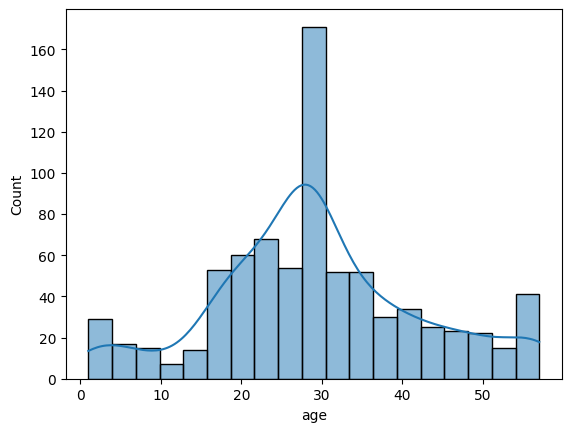

In [20]:
sns.histplot(df,x="age",kde=True)

<Axes: xlabel='age', ylabel='fare'>

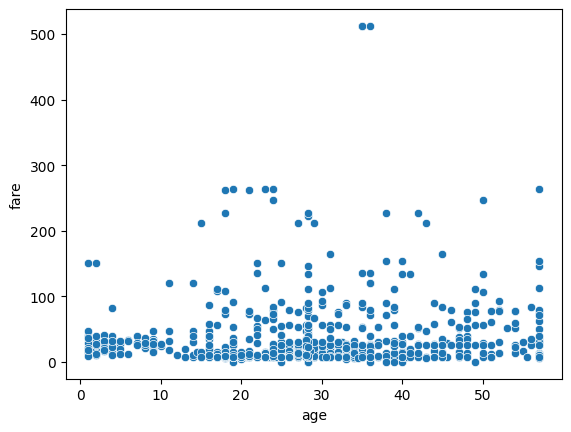

In [21]:
sns.scatterplot(df,x='age',y='fare')

In [22]:
x=df.drop(columns=['survived','sex'])
y=df['survived']

In [23]:
#from sklearn.preprocessing import StandardScaler
#sc=StandardScaler()
#df=sc.fit_transform(df)

In [24]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,avg
0,0,3,1,22.00,1,0,7.2500,2,2.416667
1,1,1,0,38.00,1,0,71.2833,0,71.283300
2,1,3,0,26.00,0,0,7.9250,2,2.641667
3,1,1,0,35.00,1,0,53.1000,2,53.100000
4,0,3,1,35.00,0,0,8.0500,2,2.683333
...,...,...,...,...,...,...,...,...,...
885,0,3,0,39.00,0,5,29.1250,1,9.708333
887,1,1,0,19.00,0,0,30.0000,2,30.000000
888,0,3,0,28.25,1,2,23.4500,2,7.816667
889,1,1,1,26.00,0,0,30.0000,0,30.000000


In [25]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [26]:
from sklearn.linear_model import LogisticRegression
lg=LogisticRegression()
lg.fit(x_train,y_train)
lg_pred=lg.predict(x_test)





In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
cm=confusion_matrix(y_test,lg_pred)
lg_acc=accuracy_score(y_test,lg_pred)
lg_pre=precision_score(y_test,lg_pred)
lg_rec=recall_score(y_test,lg_pred)
lg_f1=f1_score(y_test,lg_pred)
lg_cm=confusion_matrix(y_test,lg_pred)

In [28]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)
knn_pred=knn.predict(x_test)

In [37]:
knn_acc=accuracy_score(y_test,knn_pred)
knn_pre=precision_score(y_test,knn_pred)
knn_rec=recall_score(y_test,knn_pred)
knn_f1=f1_score(y_test,knn_pred)
knn_cm=confusion_matrix(y_test,knn_pred)

In [30]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
dt_pred=dt.predict(x_test)

In [38]:
dt_acc=accuracy_score(y_test,dt_pred)
dt_pre=precision_score(y_test,dt_pred)
dt_rec=recall_score(y_test,dt_pred)
dt_f1=f1_score(y_test,dt_pred)
dt_cm=confusion_matrix(y_test,dt_pred)

In [32]:
from sklearn.naive_bayes import GaussianNB
nb=GaussianNB()
nb.fit(x_train,y_train)
nb_pred=nb.predict(x_test)

In [39]:
nb_acc=accuracy_score(y_test,nb_pred)
nb_pre=precision_score(y_test,nb_pred)
nb_rec=recall_score(y_test,nb_pred)
nb_f1=f1_score(y_test,nb_pred)
nb_cm=confusion_matrix(y_test,nb_pred)

In [34]:
from sklearn.svm import SVC
svm=SVC()
svm.fit(x_train,y_train)
svm_pred=svm.predict(x_test)

In [40]:
svm_acc=accuracy_score(y_test,svm_pred)
svm_pre=precision_score(y_test,svm_pred)
svm_rec=recall_score(y_test,svm_pred)
svm_f1=f1_score(y_test,svm_pred)
svm_cm=confusion_matrix(y_test,svm_pred)

In [41]:
# 1. Compare ALL five classifiers (run after the existing training/evaluation cells)
from sklearn.metrics import roc_auc_score, confusion_matrix

model_objects = {
    'Logistic Regression': lg,
    'KNN': knn,
    'Decision Tree': dt,
    'Naive Bayes': nb,
    'SVM': svm
}

prediction_sets = {
    'Logistic Regression': lg_pred,
    'KNN': knn_pred,
    'Decision Tree': dt_pred,
    'Naive Bayes': nb_pred,
    'SVM': svm_pred
}

# Use the metrics that you calculated in your existing cells.
metrics_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN', 'Decision Tree', 'Naive Bayes', 'SVM'],
    'Accuracy': [lg_acc, knn_acc, dt_acc, nb_acc, svm_acc],
    'Precision': [lg_pre, knn_pre, dt_pre, nb_pre, svm_pre],
    'Recall': [lg_rec, knn_rec, dt_rec, nb_rec, svm_rec],
    'F1-score': [lg_f1, knn_f1, dt_f1, nb_f1, svm_f1]
})

# Optional ROC-AUC (SVM uses its decision-function scores, no need for probability=True)
def get_roc_auc(model):
    if hasattr(model, 'predict_proba'):
        scores = model.predict_proba(x_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        scores = model.decision_function(x_test)
    else:
        return float('nan')
    return roc_auc_score(y_test, scores)

metrics_df['ROC-AUC'] = [get_roc_auc(model_objects[name]) for name in metrics_df['Model']]

metrics_df = metrics_df.sort_values(
    by=['F1-score', 'Recall', 'Accuracy'], ascending=False
).reset_index(drop=True)

print('Classification Metrics Comparison (test set):')
display(metrics_df.round(4))

Classification Metrics Comparison (test set):


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,KNN,0.6688,0.6441,0.5507,0.5938,0.6973
1,Logistic Regression,0.6497,0.6250,0.5072,0.5600,0.7087
2,Decision Tree,0.6242,0.5833,0.5072,0.5426,0.6202
3,SVM,0.6815,0.7436,0.4203,0.5370,0.7197
4,Naive Bayes,0.6624,0.7000,0.4058,0.5138,0.6698


In [42]:
# 2. Automatically select the best model by F1-score (then Recall, Accuracy)
best_name = metrics_df.iloc[0]['Model']
best_pred = prediction_sets[best_name]
best_scores = metrics_df.iloc[0]

print(f'Best performing model: {best_name}')
print(f"Accuracy : {best_scores['Accuracy']:.4f}")
print(f"Precision: {best_scores['Precision']:.4f}")
print(f"Recall   : {best_scores['Recall']:.4f}")
print(f"F1-score : {best_scores['F1-score']:.4f}")
print(f"ROC-AUC  : {best_scores['ROC-AUC']:.4f}")

Best performing model: KNN
Accuracy : 0.6688
Precision: 0.6441
Recall   : 0.5507
F1-score : 0.5938
ROC-AUC  : 0.6973


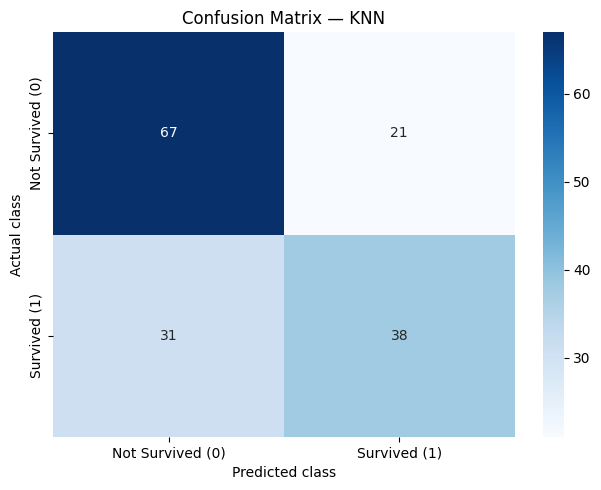

True Negatives (TN): 67 | False Positives (FP): 21
False Negatives (FN): 31 | True Positives (TP): 38


In [43]:
# 3. Confusion matrix for the best model knn
best_cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

plt.figure(figsize=(6.5, 5))
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Survived (0)', 'Survived (1)'],
            yticklabels=['Not Survived (0)', 'Survived (1)'])
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.title(f'Confusion Matrix — {best_name}')
plt.tight_layout()
plt.show()

print(f'True Negatives (TN): {best_cm[0,0]} | False Positives (FP): {best_cm[0,1]}')
print(f'False Negatives (FN): {best_cm[1,0]} | True Positives (TP): {best_cm[1,1]}')

In [44]:
# 4. Data-driven 2–3 sentence justification for the assignment
summary = (
    f"I selected {best_name} as the best classification model because it achieved "
    f"the highest F1-score ({best_scores['F1-score']:.3f}) among the five tested models, "
    f"with an accuracy of {best_scores['Accuracy']:.3f}, precision of "
    f"{best_scores['Precision']:.3f}, and recall of {best_scores['Recall']:.3f}. "
    f"Its confusion matrix shows {best_cm[1, 1]} correctly predicted survivors and "
    f"{best_cm[0, 0]} correctly predicted non-survivors, with "
    f"{best_cm[0, 1] + best_cm[1, 0]} total misclassifications. "
    f"Its ROC-AUC of {best_scores['ROC-AUC']:.3f} further indicates how well "
    f"it separates survivors from non-survivors."
)
print(summary)

I selected KNN as the best classification model because it achieved the highest F1-score (0.594) among the five tested models, with an accuracy of 0.669, precision of 0.644, and recall of 0.551. Its confusion matrix shows 38 correctly predicted survivors and 67 correctly predicted non-survivors, with 52 total misclassifications. Its ROC-AUC of 0.697 further indicates how well it separates survivors from non-survivors.
